# Trabajo Práctico: Análisis Exploratorio de Datos en Python

**Estudiante:** Luis Alfredo Fiedler Fiedler

**Región elegida:** Región de Valparaíso

**Definición del estudio:**


1.   *Contexto:* Análisis descriptivo para caracterizar el perfil demográfico, académico y financiero de los estudiantes matriculados, permitiendo identificar patrones de distribución institucional y de aranceles.
2.   *Población*: El conjunto total de estudiantes matriculados en instituciones de Educación Superior en la región de Valparaíso durante el año 2021.
3.   *Muestra*: Los registros contenidos en la base de datos representa un subconjunto (o la totalidad censal) de la población de interés.
4.   *Unidad de análisis*: Cada estudiante individualmente matriculado en una institución de educación superior de la región.



In [ ]:
# Carga de librerias y base de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATOS = pd.read_excel("06_MATRICULAS_ED_SUPERIOR_VALPARAISO_2021.xlsx")

# Configuración de estilo para matplotlib
plt.style.use('default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

# Exploración inicial
print("--- Primeros 5 registros ---")
display(DATOS.head())

print("\n--- Estructura general del dataset ---")
DATOS.info()

--- Primeros 5 registros ---


,ID,GENERO,EDAD,RANGO EDAD,AÑO INGRESO,SEMESTRE INGRESO,TIPO DE INSTITUCION,NOMBRE DE INSTITUCION,ACREDITACION INSTITUCIONAL,PERIODO DE ACREDITACION,...,NIVEL CARRERA,AREA CONOCIMIENTO,DURACION PLAN DE ESTUDIO (SEMESTRES),DURACION PROCESO TITULACION (SEMESTRES),DURACION TOTAL CARRERA (SEMESTRES),VALOR MATRICULA (PESOS),VALOR ARANCEL (PESOS),REGION SEDE,PROVINCIA SEDE,COMUNA SEDE
0,10,Femenino,24,20 a 24,2016,Primer semestre,Universidades Privadas,UNIVERSIDAD SANTO TOMAS,ACREDITADA,31/03/2021 AL 31/03/2025,...,Carreras Profesionales,Salud,10,0,10,130000,3713000,Valparaiso,Valparaiso,Vina Del Mar
1,25,Femenino,19,15 a 19,2021,Primer semestre,Institutos Profesionales,IP INSTITUTO DE ESTUDIOS BANCARIOS GUILLERMO S...,ACREDITADA,17/12/2017 AL 17/12/2022,...,Carreras Profesionales,Administracion y Comercio,8,0,8,190000,1900000,Valparaiso,Valparaiso,Vina Del Mar
2,28,Masculino,24,20 a 24,2019,Primer semestre,Institutos Profesionales,IP AIEP,ACREDITADA,22/10/2017 AL 22/10/2022,...,Carreras Profesionales,Administracion y Comercio,8,1,8,190000,1760000,Valparaiso,San Felipe De Aconcagua,San Felipe
3,29,Masculino,24,20 a 24,2015,Primer semestre,Universidades CRUCH,PONTIFICIA UNIVERSIDAD CATOLICA DE VALPARAISO,ACREDITADA,26/11/2015 AL 26/11/2021,...,Carreras Profesionales,Educacion,9,0,9,208000,2558000,Valparaiso,Valparaiso,Valparaiso
4,42,Masculino,26,25 a 29,2014,Primer semestre,Universidades CRUCH,UNIVERSIDAD TECNICA FEDERICO SANTA MARIA,ACREDITADA,29/12/2016 AL 29/12/2022,...,Carreras Profesionales,Arte y Arquitectura,10,1,11,186000,4350000,Valparaiso,Valparaiso,Valparaiso



--- Estructura general del dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109198 entries, 0 to 109197
Data columns (total 28 columns):
 #   Column                                   Non-Null Count   Dtype  
---  ------                                   --------------   -----  
 0   ID                                       109198 non-null  int64  
 1   GENERO                                   109198 non-null  object 
 2   EDAD                                     109198 non-null  int64  
 3   RANGO EDAD                               109198 non-null  object 
 4   AÑO INGRESO                              109198 non-null  int64  
 5   SEMESTRE INGRESO                         109198 non-null  object 
 6   TIPO DE INSTITUCION                      109198 non-null  object 
 7   NOMBRE DE INSTITUCION                    109198 non-null  object 
 8   ACREDITACION INSTITUCIONAL               109198 non-null  object 
 9   PERIODO DE ACREDITACION                  104580 non-null  objec

## Clasificación de Variables

*   **Cualitativa Nominal:** GENERO, JORNADA, TIPO DE INSTITUCION, AREA CONOCIMIENTO (Categorías sin orden inherente).
*   **Cualitativa Ordinal:** RANGO EDAD, ACREDITACION INSTITUCIONAL, NIVEL CARRERA, SEMESTRE INGRESO (Categorías con un orden o jerarquía lógica).
*   **Cuantitativa Discreta:** EDAD, AÑOS DE ACREDITACION, DURACION PLAN DE ESTUDIO (SEMESTRES), DURACION TOTAL CARRERA (SEMESTRES) (Valores numéricos contables, generalmente enteros).
*   **Cuantitativa Continua:** VALOR MATRICULA (PESOS), VALOR ARANCEL (PESOS) (Valores numéricos medibles en un rango continuo, tratados como continuos por su amplia escala para fines de agrupación en intervalos).



## Selección de variables para el análisis

*   **Variables Cualitativas:** GENERO, JORNADA, RANGO EDAD, ACREDITACION INSTITUCIONAL.
*   **Variables Cuantitativas:** EDAD (Discreta), DURACION TOTAL CARRERA (SEMESTRES) (Discreta), VALOR MATRICULA (PESOS) (Continua), VALOR ARANCEL (PESOS) (Continua).

=== 1. GENERO ===


,GENERO,fi,hi
0,Femenino,58251,0.533444
1,Masculino,50947,0.466556


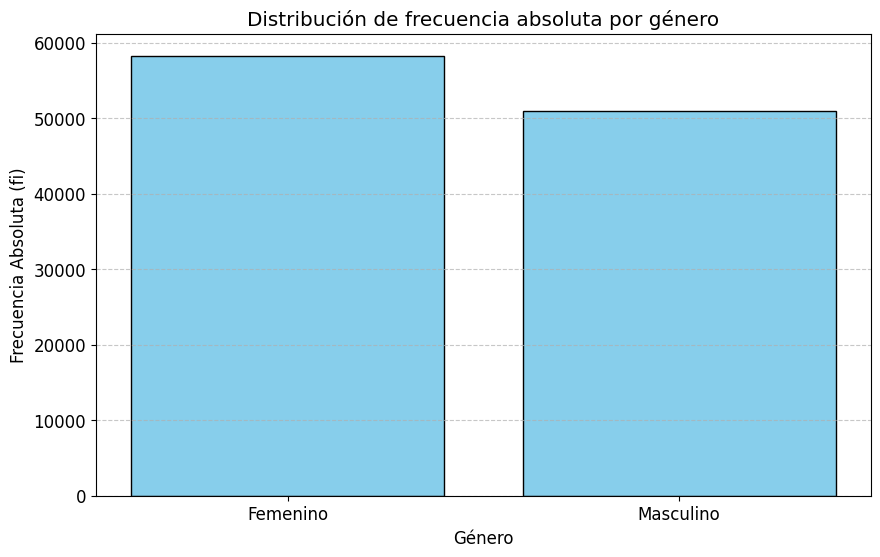

Moda: Femenino
Interpretación: La modalidad de género predominante en la matrícula es un indicador clave de la composición demográfica. La moda nos señala cuál grupo es el mayoritario sin ambigüedades.


In [ ]:
# Análisis de variables cualitativas

# Función auxiliar para tablas de frecuencia cualitativa
def tabla_fcual(DATOS, col):
    tabla = DATOS[col].value_counts(dropna=False).reset_index()
    tabla.columns = [col, 'fi']
    tabla['hi'] = tabla['fi'] / tabla['fi'].sum()
    return tabla

# 1. Variable: GENERO
print("=== 1. GENERO ===")
tabla_genero = tabla_fcual(DATOS, 'GENERO')
display(tabla_genero)

plt.bar(tabla_genero['GENERO'].astype(str), tabla_genero['fi'], color='skyblue', edgecolor='black')
plt.title('Distribución de frecuencia absoluta por género')
plt.xlabel('Género')
plt.ylabel('Frecuencia Absoluta (fi)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

moda_genero = DATOS['GENERO'].mode()[0]
print(f"Moda: {moda_genero}")
print("Interpretación: La modalidad de género predominante en la matrícula es un indicador clave de la composición demográfica. La moda nos señala cuál grupo es el mayoritario sin ambigüedades.")

=== 2. JORNADA ===


,JORNADA,fi,hi
0,Diurno,86826,0.795124
1,Vespertino,20051,0.183621
2,Otro,997,0.009130
3,A Distancia,663,0.006072
4,Semipresencial,661,0.006053


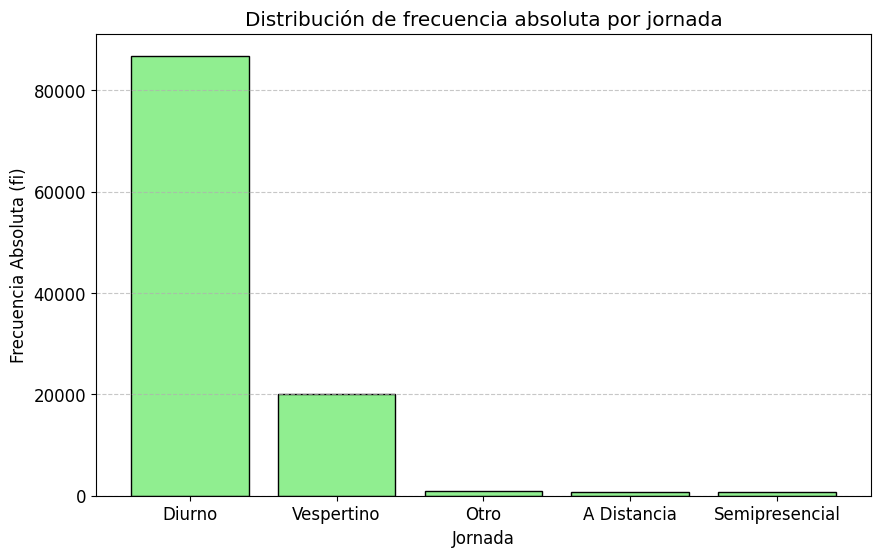

Moda: Diurno
Interpretación: La jornada con mayor frecuencia absoluta revela la preferencia o disponibilidad horaria mayoritaria del estudiantado en la región, siendo fundamental para la planificación académica institucional.


In [ ]:
# 2. Variable: JORNADA
print("=== 2. JORNADA ===")
tabla_jornada = tabla_fcual(DATOS, 'JORNADA')
display(tabla_jornada)

plt.bar(tabla_jornada['JORNADA'].astype(str), tabla_jornada['fi'], color='lightgreen', edgecolor='black')
plt.title('Distribución de frecuencia absoluta por jornada')
plt.xlabel('Jornada')
plt.ylabel('Frecuencia Absoluta (fi)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

moda_jornada = DATOS['JORNADA'].mode()[0]
print(f"Moda: {moda_jornada}")
print("Interpretación: La jornada con mayor frecuencia absoluta revela la preferencia o disponibilidad horaria mayoritaria del estudiantado en la región, siendo fundamental para la planificación académica institucional.")

=== 3. RANGO EDAD ===


,RANGO EDAD,fi,hi
0,20 a 24,55143,0.504982
1,15 a 19,19295,0.176697
2,25 a 29,18349,0.168034
3,30 a 34,7660,0.070148
4,40 y mas,4665,0.042721
5,35 a 39,4086,0.037418


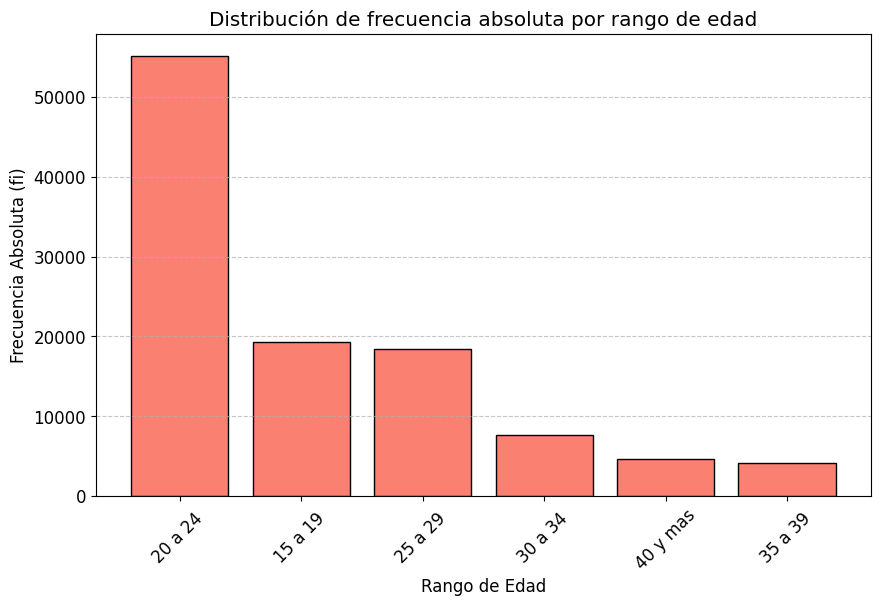

Moda: 20 a 24 
Interpretación: Al ser una variable ordinal, la moda indica el grupo etario más frecuente. Esto permite identificar si la educación superior en la región está concentrada en estudiantes tradicionales o en población adulta.


In [ ]:
# 3. Variable: RANGO EDAD
print("=== 3. RANGO EDAD ===")
tabla_rango = tabla_fcual(DATOS, 'RANGO EDAD')
display(tabla_rango)

plt.bar(tabla_rango['RANGO EDAD'].astype(str), tabla_rango['fi'], color='salmon', edgecolor='black')
plt.title('Distribución de frecuencia absoluta por rango de edad')
plt.xlabel('Rango de Edad')
plt.ylabel('Frecuencia Absoluta (fi)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

moda_rango = DATOS['RANGO EDAD'].mode()[0]
print(f"Moda: {moda_rango}")
print("Interpretación: Al ser una variable ordinal, la moda indica el grupo etario más frecuente. Esto permite identificar si la educación superior en la región está concentrada en estudiantes tradicionales o en población adulta.")

=== 4. ACREDITACION INSTITUCIONAL ===


,ACREDITACION INSTITUCIONAL,fi,hi
0,ACREDITADA,104580,0.95771
1,NO ACREDITADA,4618,0.04229


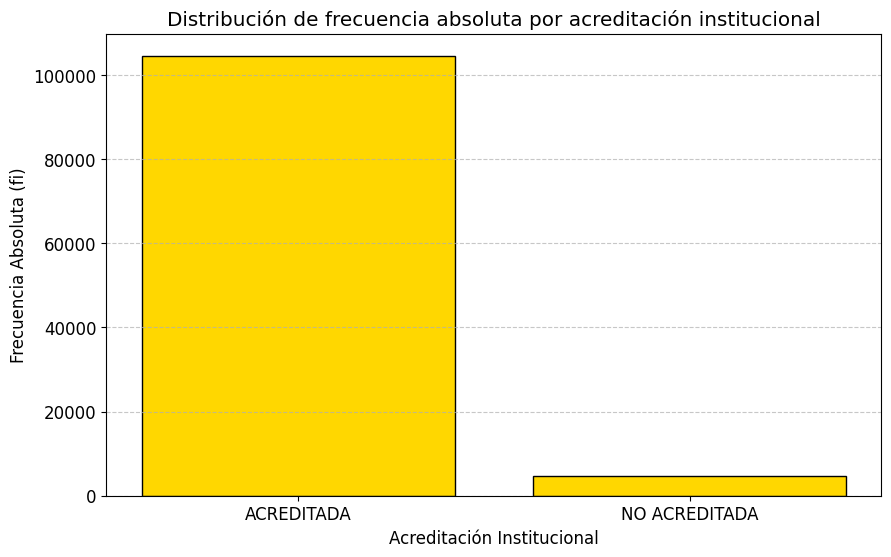

Moda: ACREDITADA
Interpretación: La moda en esta variable refleja si la mayoría de los estudiantes matriculados se concentran en instituciones que cuentan con acreditación vigente, un proxy importante de la calidad percibida o accesibilidad.


In [ ]:
# 4. Variable: ACREDITACION INSTITUCIONAL
print("=== 4. ACREDITACION INSTITUCIONAL ===")
tabla_acred = tabla_fcual(DATOS, 'ACREDITACION INSTITUCIONAL')
display(tabla_acred)

plt.bar(tabla_acred['ACREDITACION INSTITUCIONAL'].astype(str), tabla_acred['fi'], color='gold', edgecolor='black')
plt.title('Distribución de frecuencia absoluta por acreditación institucional')
plt.xlabel('Acreditación Institucional')
plt.ylabel('Frecuencia Absoluta (fi)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

moda_acred = DATOS['ACREDITACION INSTITUCIONAL'].mode()[0]
print(f"Moda: {moda_acred}")
print("Interpretación: La moda en esta variable refleja si la mayoría de los estudiantes matriculados se concentran en instituciones que cuentan con acreditación vigente, un proxy importante de la calidad percibida o accesibilidad.")

=== 1. EDAD (Discreta) ===


,EDAD,fi,hi,Fi,Hi
0,16,1,0.000009,1,0.000009
1,17,6,0.000055,7,0.000064
2,18,3058,0.028004,3065,0.028068
3,19,16230,0.148629,19295,0.176697
4,20,6412,0.058719,25707,0.235416
5,21,13249,0.121330,38956,0.356746
6,22,12203,0.111751,51159,0.468498
7,23,10701,0.097996,61860,0.566494
8,24,12578,0.115185,74438,0.681679
9,25,2836,0.025971,77274,0.707650


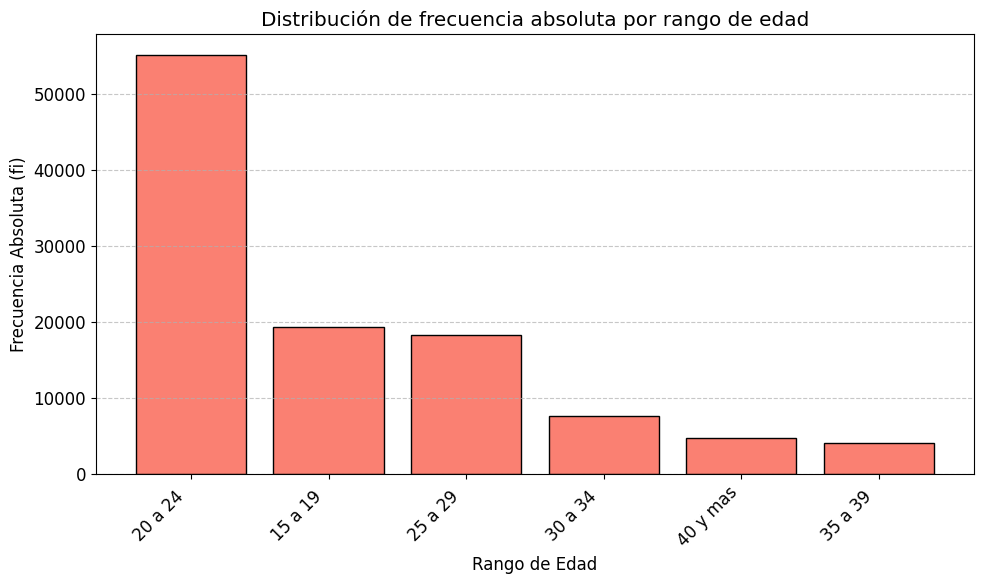

Tendencia Central: Media = 24.69, Mediana = 23.00, Moda = 19
Posición (Percentiles): P25 = 21.0, P50 = 23.0, P75 = 26.0
Dispersión: Varianza = 42.74, Desv. Estándar = 6.54, CV = 26.48%
Interpretación: La edad presenta una dispersión relativa (CV) moderada. La proximidad entre media y mediana sugiere una distribución relativamente simétrica, concentrada en la edad típica de ingreso a la educación superior.


In [ ]:
#Análisis de variables cuantitativas

# 1. Variable Cuantitativa Discreta: EDAD
print("=== 1. EDAD (Discreta) ===")
# Tabla de frecuencias no agrupada (Discreta)
tabla_edad = DATOS['EDAD'].value_counts(dropna=False).sort_index().reset_index()
tabla_edad.columns = ['EDAD', 'fi']
tabla_edad['hi'] = tabla_edad['fi'] / tabla_edad['fi'].sum()
tabla_edad['Fi'] = tabla_edad['fi'].cumsum()
tabla_edad['Hi'] = tabla_edad['hi'].cumsum()
display(tabla_edad)

# Gráfico
plt.bar(tabla_rango['RANGO EDAD'].astype(str), tabla_rango['fi'], color='salmon', edgecolor='black')
plt.title('Distribución de frecuencia absoluta por rango de edad')
plt.xlabel('Rango de Edad')
plt.ylabel('Frecuencia Absoluta (fi)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

# Medidas estadísticas
media_edad = DATOS['EDAD'].mean()
mediana_edad = DATOS['EDAD'].median()
moda_edad = DATOS['EDAD'].mode()[0]
p25_edad = DATOS['EDAD'].quantile(0.25)
p50_edad = DATOS['EDAD'].quantile(0.50)
p75_edad = DATOS['EDAD'].quantile(0.75)
var_edad = DATOS['EDAD'].var()
std_edad = DATOS['EDAD'].std()
cv_edad = (std_edad / media_edad) * 100

print(f"Tendencia Central: Media = {media_edad:.2f}, Mediana = {mediana_edad:.2f}, Moda = {moda_edad}")
print(f"Posición (Percentiles): P25 = {p25_edad}, P50 = {p50_edad}, P75 = {p75_edad}")
print(f"Dispersión: Varianza = {var_edad:.2f}, Desv. Estándar = {std_edad:.2f}, CV = {cv_edad:.2f}%")
print("Interpretación: La edad presenta una dispersión relativa (CV) moderada. La proximidad entre media y mediana sugiere una distribución relativamente simétrica, concentrada en la edad típica de ingreso a la educación superior.")

=== 2. DURACION TOTAL CARRERA (SEMESTRES) (Discreta) ===


,DURACION TOTAL CARRERA (SEMESTRES),fi,hi,Fi,Hi
0,1,338,0.003095,338,0.003095
1,2,615,0.005632,953,0.008727
2,3,930,0.008517,1883,0.017244
3,4,5923,0.054241,7806,0.071485
4,5,22795,0.208749,30601,0.280234
5,6,3252,0.029781,33853,0.310015
6,7,1320,0.012088,35173,0.322103
7,8,18555,0.169921,53728,0.492024
8,9,7167,0.065633,60895,0.557657
9,10,32949,0.301736,93844,0.859393


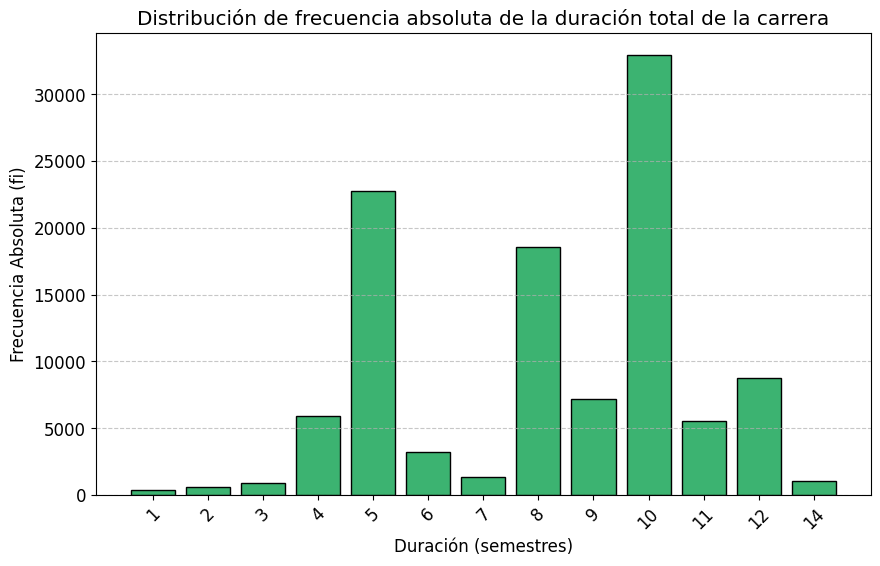

Tendencia Central: Media = 8.19, Mediana = 9.00, Moda = 10
Posición (Percentiles): P25 = 5.0, P50 = 9.0, P75 = 10.0
Dispersión: Varianza = 6.78, Desv. Estándar = 2.60, CV = 31.79%
Interpretación: La duración total muestra una baja dispersión relativa (CV bajo), lo que indica que la mayoría de las carreras se agrupan en torno a una duración estándar (ej. 8-10 semestres), con pocas carreras de duración atípica.


In [ ]:
# 2. Variable Cuantitativa Discreta: DURACION TOTAL CARRERA (SEMESTRES)
print("=== 2. DURACION TOTAL CARRERA (SEMESTRES) (Discreta) ===")
tabla_duracion = DATOS['DURACION TOTAL CARRERA (SEMESTRES)'].value_counts(dropna=False).sort_index().reset_index()
tabla_duracion.columns = ['DURACION TOTAL CARRERA (SEMESTRES)', 'fi']
tabla_duracion['hi'] = tabla_duracion['fi'] / tabla_duracion['fi'].sum()
tabla_duracion['Fi'] = tabla_duracion['fi'].cumsum()
tabla_duracion['Hi'] = tabla_duracion['hi'].cumsum()
display(tabla_duracion)

# Gráfico
plt.bar(tabla_duracion['DURACION TOTAL CARRERA (SEMESTRES)'].astype(str), tabla_duracion['fi'], color='mediumseagreen', edgecolor='black')
plt.title('Distribución de frecuencia absoluta de la duración total de la carrera')
plt.xlabel('Duración (semestres)')
plt.ylabel('Frecuencia Absoluta (fi)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Medidas Estadísticas
col_dur = 'DURACION TOTAL CARRERA (SEMESTRES)'
media_dur = DATOS[col_dur].mean()
mediana_dur = DATOS[col_dur].median()
moda_dur = DATOS[col_dur].mode()[0]
p25_dur = DATOS[col_dur].quantile(0.25)
p50_dur = DATOS[col_dur].quantile(0.50)
p75_dur = DATOS[col_dur].quantile(0.75)
var_dur = DATOS[col_dur].var()
std_dur = DATOS[col_dur].std()
cv_dur = (std_dur / media_dur) * 100

print(f"Tendencia Central: Media = {media_dur:.2f}, Mediana = {mediana_dur:.2f}, Moda = {moda_dur}")
print(f"Posición (Percentiles): P25 = {p25_dur}, P50 = {p50_dur}, P75 = {p75_dur}")
print(f"Dispersión: Varianza = {var_dur:.2f}, Desv. Estándar = {std_dur:.2f}, CV = {cv_dur:.2f}%")
print("Interpretación: La duración total muestra una baja dispersión relativa (CV bajo), lo que indica que la mayoría de las carreras se agrupan en torno a una duración estándar (ej. 8-10 semestres), con pocas carreras de duración atípica.")

=== 3. VALOR MATRICULA (PESOS) (Continua) ===


,Intervalo,fi,hi,Fi,Hi
0,"[0, 380080)",98481,0.901857,98481,0.901857
1,"[380080, 760160)",10711,0.098088,109192,0.999945
2,"[760160, 1140240)",0,0.000000,109192,0.999945
3,"[1140240, 1520320)",0,0.000000,109192,0.999945
4,"[1520320, 1900400)",0,0.000000,109192,0.999945
5,"[1900400, 2280480)",0,0.000000,109192,0.999945
6,"[2280480, 2660560)",0,0.000000,109192,0.999945
7,"[2660560, 3040640)",0,0.000000,109192,0.999945
8,"[3040640, 3420720)",0,0.000000,109192,0.999945
9,"[3420720, 3800800)",6,0.000055,109198,1.000000


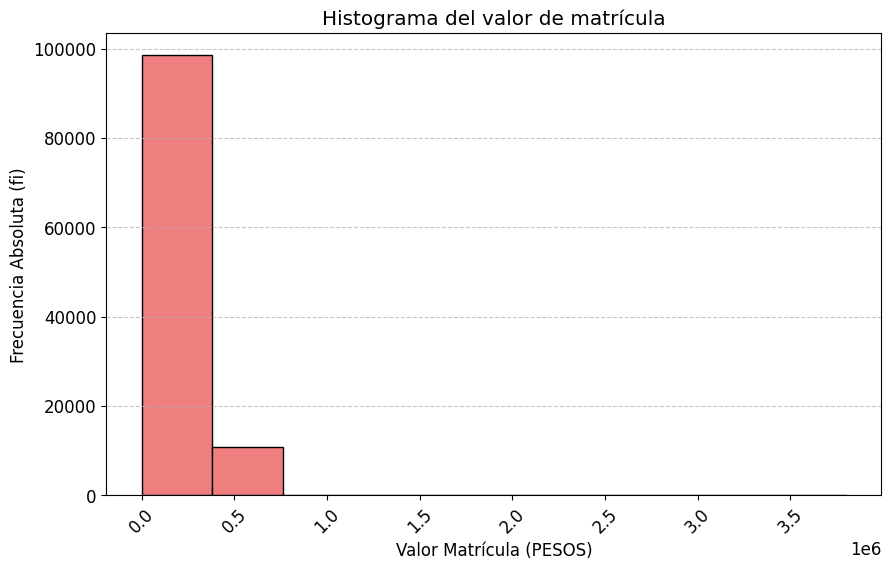

Tendencia Central: Media = $219,393, Mediana = $190,000, Moda = $176,000
Posición (Percentiles): P25 = $176,000, P50 = $190,000, P75 = $216,000
Dispersión: Varianza = 13,028,471,811, Desv. Estándar = $114,142, CV = 52.03%
Interpretación: El alto Coeficiente de Variación indica una fuerte dispersión en los costos de matrícula. La media es probablemente mayor que la mediana, sugiriendo un sesgo positivo (colas hacia valores altos) debido a instituciones con matrículas significativamente más elevadas.


In [ ]:
# 3. Variable Cuantitativa Continua: VALOR MATRICULA (PESOS)
print("=== 3. VALOR MATRICULA (PESOS) (Continua) ===")
# Agrupación en intervalos
num_bins = 10
min_val = DATOS['VALOR MATRICULA (PESOS)'].min()
max_val = DATOS['VALOR MATRICULA (PESOS)'].max()
bins_matricula = np.linspace(min_val, max_val, num_bins + 1)
etiquetas_matricula = [f"[{int(bins_matricula[i])}, {int(bins_matricula[i+1])})" for i in range(len(bins_matricula)-1)]

df_temp_mat = DATOS.copy()
df_temp_mat['Intervalo'] = pd.cut(df_temp_mat['VALOR MATRICULA (PESOS)'], bins=bins_matricula, labels=etiquetas_matricula, include_lowest=True)

tabla_matricula = df_temp_mat['Intervalo'].value_counts(sort=False).reset_index()
tabla_matricula.columns = ['Intervalo', 'fi']
tabla_matricula['hi'] = tabla_matricula['fi'] / tabla_matricula['fi'].sum()
tabla_matricula['Fi'] = tabla_matricula['fi'].cumsum()
tabla_matricula['Hi'] = tabla_matricula['hi'].cumsum()
display(tabla_matricula)

# Gráfico
plt.hist(DATOS['VALOR MATRICULA (PESOS)'].dropna(), bins=bins_matricula, color='lightcoral', edgecolor='black')
plt.title('Histograma del valor de matrícula')
plt.xlabel('Valor Matrícula (PESOS)')
plt.ylabel('Frecuencia Absoluta (fi)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Medidas Estadísticas
media_mat = DATOS['VALOR MATRICULA (PESOS)'].mean()
mediana_mat = DATOS['VALOR MATRICULA (PESOS)'].median()
moda_mat = DATOS['VALOR MATRICULA (PESOS)'].mode()[0]
p25_mat = DATOS['VALOR MATRICULA (PESOS)'].quantile(0.25)
p50_mat = DATOS['VALOR MATRICULA (PESOS)'].quantile(0.50)
p75_mat = DATOS['VALOR MATRICULA (PESOS)'].quantile(0.75)
var_mat = DATOS['VALOR MATRICULA (PESOS)'].var()
std_mat = DATOS['VALOR MATRICULA (PESOS)'].std()
cv_mat = (std_mat / media_mat) * 100

print(f"Tendencia Central: Media = ${media_mat:,.0f}, Mediana = ${mediana_mat:,.0f}, Moda = ${moda_mat:,.0f}")
print(f"Posición (Percentiles): P25 = ${p25_mat:,.0f}, P50 = ${p50_mat:,.0f}, P75 = ${p75_mat:,.0f}")
print(f"Dispersión: Varianza = {var_mat:,.0f}, Desv. Estándar = ${std_mat:,.0f}, CV = {cv_mat:.2f}%")
print("Interpretación: El alto Coeficiente de Variación indica una fuerte dispersión en los costos de matrícula. La media es probablemente mayor que la mediana, sugiriendo un sesgo positivo (colas hacia valores altos) debido a instituciones con matrículas significativamente más elevadas.")

=== 4. VALOR ARANCEL (PESOS) ===


,Intervalo,fi,hi,Fi,Hi
0,"[0, 1150000)",1487,0.013617,1487,0.013617
1,"[1150000, 2300000)",35138,0.321782,36625,0.335400
2,"[2300000, 3450000)",31530,0.288742,68155,0.624141
3,"[3450000, 4600000)",25490,0.233429,93645,0.857571
4,"[4600000, 5750000)",12343,0.113033,105988,0.970604
5,"[5750000, 6900000)",1532,0.014030,107520,0.984633
6,"[6900000, 8050000)",1481,0.013563,109001,0.998196
7,"[8050000, 9200000)",149,0.001364,109150,0.999560
8,"[9200000, 10350000)",16,0.000147,109166,0.999707
9,"[10350000, 11500000)",32,0.000293,109198,1.000000


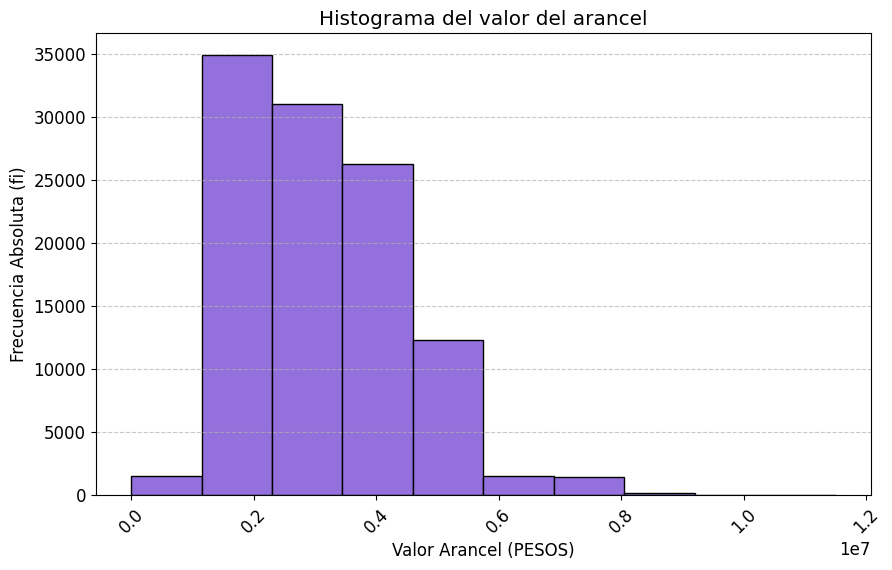

Tendencia Central: Media = $3,141,605, Mediana = $2,899,000, Moda = $4,740,000
Posición (Percentiles): P25 = $2,130,000, P50 = $2,899,000, P75 = $4,235,000
Dispersión: Varianza = 1,614,497,552,116, Desv. Estándar = $1,270,629, CV = 40.45%
Interpretación: Similar a la matrícula, el arancel presenta una alta dispersión relativa. El percentil 75 revela el umbral superior del 75% de los estudiantes, evidenciando una brecha económica significativa entre las instituciones de menor y mayor costo en la región.


In [ ]:
# 4. Variable Cuantitativa Continua: VALOR ARANCEL (PESOS)
print("=== 4. VALOR ARANCEL (PESOS) ===")
# Agrupación en intervalos
min_val_arr = DATOS['VALOR ARANCEL (PESOS)'].min()
max_val_arr = DATOS['VALOR ARANCEL (PESOS)'].max()
bins_arancel = np.linspace(min_val_arr, max_val_arr, num_bins + 1)
etiquetas_arancel = [f"[{int(bins_arancel[i])}, {int(bins_arancel[i+1])})" for i in range(len(bins_arancel)-1)]

df_temp_arr = DATOS.copy()
df_temp_arr['Intervalo'] = pd.cut(df_temp_arr['VALOR ARANCEL (PESOS)'], bins=bins_arancel, labels=etiquetas_arancel, include_lowest=True)

tabla_arancel = df_temp_arr['Intervalo'].value_counts(sort=False).reset_index()
tabla_arancel.columns = ['Intervalo', 'fi']
tabla_arancel['hi'] = tabla_arancel['fi'] / tabla_arancel['fi'].sum()
tabla_arancel['Fi'] = tabla_arancel['fi'].cumsum()
tabla_arancel['Hi'] = tabla_arancel['hi'].cumsum()
display(tabla_arancel)

# Gráfico: Histograma (Barras pegadas, Regla Estricta)
plt.hist(DATOS['VALOR ARANCEL (PESOS)'].dropna(), bins=bins_arancel, color='mediumpurple', edgecolor='black')
plt.title('Histograma del valor del arancel')
plt.xlabel('Valor Arancel (PESOS)')
plt.ylabel('Frecuencia Absoluta (fi)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Medidas Estadísticas (sobre datos originales para precisión)
media_arr = DATOS['VALOR ARANCEL (PESOS)'].mean()
mediana_arr = DATOS['VALOR ARANCEL (PESOS)'].median()
moda_arr = DATOS['VALOR ARANCEL (PESOS)'].mode()[0]
p25_arr = DATOS['VALOR ARANCEL (PESOS)'].quantile(0.25)
p50_arr = DATOS['VALOR ARANCEL (PESOS)'].quantile(0.50)
p75_arr = DATOS['VALOR ARANCEL (PESOS)'].quantile(0.75)
var_arr = DATOS['VALOR ARANCEL (PESOS)'].var()
std_arr = DATOS['VALOR ARANCEL (PESOS)'].std()
cv_arr = (std_arr / media_arr) * 100

print(f"Tendencia Central: Media = ${media_arr:,.0f}, Mediana = ${mediana_arr:,.0f}, Moda = ${moda_arr:,.0f}")
print(f"Posición (Percentiles): P25 = ${p25_arr:,.0f}, P50 = ${p50_arr:,.0f}, P75 = ${p75_arr:,.0f}")
print(f"Dispersión: Varianza = {var_arr:,.0f}, Desv. Estándar = ${std_arr:,.0f}, CV = {cv_arr:.2f}%")
print("Interpretación: Similar a la matrícula, el arancel presenta una alta dispersión relativa. El percentil 75 revela el umbral superior del 75% de los estudiantes, evidenciando una brecha económica significativa entre las instituciones de menor y mayor costo en la región.")